## Including a crop model

In [2]:
""" 
Imports needed for running the code
"""
# Ignore warnings during ODE solving
# Typically such warnings should be checked,
# but for the current exercise it is not important
import warnings
warnings.filterwarnings("ignore")

import os

from IPython.display import display
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import greenlight

In [19]:
crop_definition = {
    "W": {
        "description": "Crop dry mass",
        "unit": "g/m2",
        "definition": "LUE * (1 - exp(-k*LAI)) * I * 1e-6",
        "type": "state",
        "init": "75",
        "reference": "Stanghellini (2019), Eq. 2.25. " \
                    "Note that in Eq. 2.5 (Stanghellini 2019), dW/dt is given in g/m2/day. " \
                    "However, solar light is expressed there as I, in MJ/m2/day. " \
                    "Here we use I instead in W/m2 = J/m2/s (see reference for I). " \
                    "This is multiplied by 1e-6, to convert to MW/m2 = MJ/m2/s. " \
                    "Thus we use I*1e-6 which is in MJ/m2/s, instead of MJ/m2/day. " \
                    "Therefore the unit for dW/dt becomes g/m2/s instead of g/m2/day. " \
                    "The default time unit in GreenLight is s, so W is automatically in g/m2." \
                    "The initial value of 75 g/m2 is based on Fig. 2.13 (Stanghellini 2019)" \
                    "As a reasonable value for a small crop"
    },
     "LUE": {
         "description": "Light use efficiency",
         "unit": "g crop weight per MJ PAR",
         "definition": "4.3",
         "type": "const",
         "reference": "Stanghellini (2019), pg. 49. 4.3 is chosen as a middle value, see Fig. 2.13"
    },
     "k": {
         "description": "Light extinction coefficient",
         "unit": "-",
         "definition": "0.7",
         "type": "const",
         "reference": "Stanghellini (2019), pg. 49. " \
                      "The value of 0.7 is based on Stanghellini (2019), pg. 39: " \
                      "'For many greenhouse crops, k has a value between 0.6 and 0.8'"
    },
     "I": {
         "description": "Light intensity",
         "unit": "W/m2",
         "definition": "I",
         "type": "input",
         "reference": "Stanghellini (2019), pg. 49. " \
                      "Since the default time unit in GreenLight is seconds, " \
                      "It is more convenient to use I in J/m2/s = W/m2 instead of MJ/m2/day. "\
                      "This is adjusted in the definition of W, see there"
    },
    "LAI": {
        "description": "Leaf area index",
        "unit": "m2 leaf per m2 floor",
        "definition": "W * fLeaves * SLA / 10000",
        "type": "aux",
        "reference": "Stanghellini (2019), Eq. 2.26. " \
                     "Note that according to the Eq., the LAI growth rate is equal to " \
                     "crop growth rate times fLeaves * SLA / 10000. " \
                     "Therefore LAI is equal to crop dry mass times the same factor" 
    },
     "fLeaves": {
         "description": "Fraction of crop dry mass partitioned to the leaves",
         "unit": "-",
         "definition": "0.8",
         "type": "const",
         "reference": "Stanghellini (2019), Eq. 2.26. " \
                      "The value of 0.8 is chosen to represent a young vegetative crop"
    },
     "SLA": {
         "description": "Specific leaf area",
         "unit": "cm2/g",
         "definition": "250",
         "type": "const",
         "reference": "Stanghellini (2019), Box 2.26. " \
                      "The value of 250 is a middle value for tomato, "\
                      "See Stanghellini (2019), Table 2.1"
    }   
 }

n_days = 100

options = {
    "options": {
        "t_start":"0",
        "t_end": str(n_days * 24 * 60 * 60),
        "output_step": "300",
        "t_eval": "300"
    }
}

crop_mdl = greenlight.GreenLight(
    base_path=os.getcwd(), 
    input_prompt=[crop_definition, os.path.join("input", "example_weather.csv"), options], 
    output_path=os.path.join("output", "crop_output.csv")
)
crop_mdl.run()





Loading model from input\example_weather.csv
Simulation started at time (ISO format): 2026-10-19T18:18:18.306354
Running: 68.03%

Failed to interpret definition for 'I': 'I'


Running: 100.00%

NameError: name 'I' is not defined

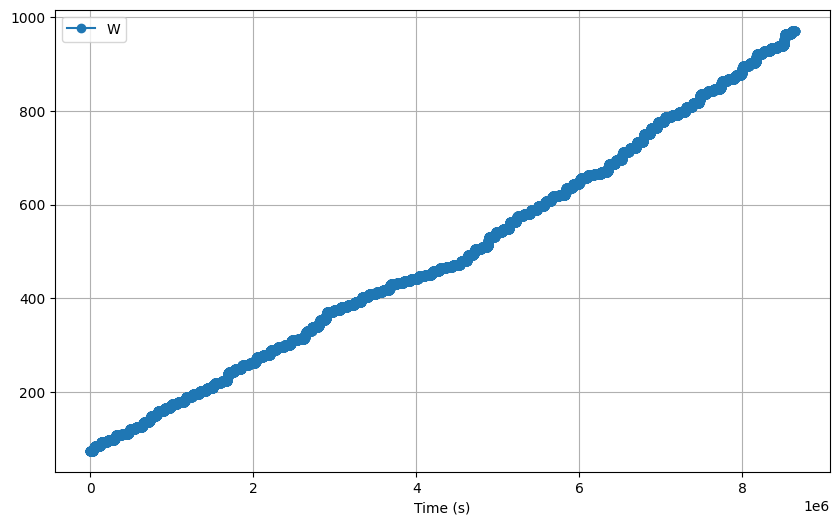

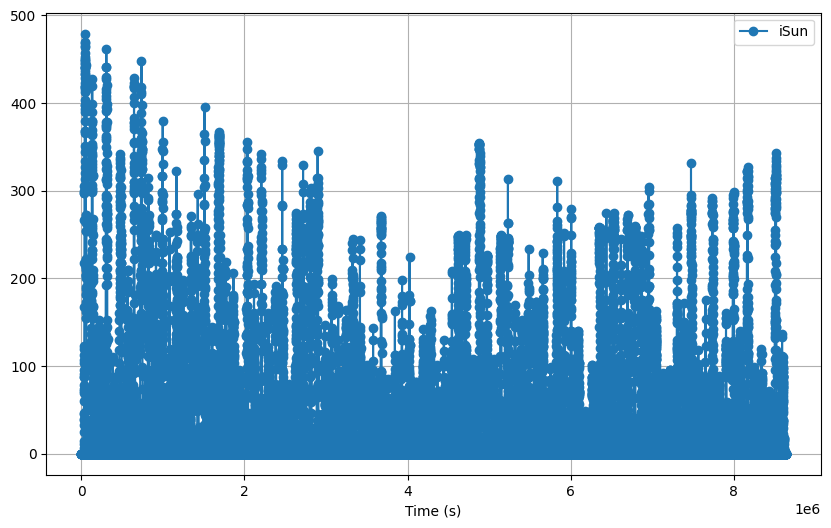

In [5]:
# Load simulation result
crop_output = pd.read_csv(os.path.join("output", "crop_output.csv"), header=[0,1,2], low_memory=False)

# Display
def display_output(output_df, chosen_vars, titles, ylabels, line_style):
    axes = []
    
    for vars_to_plot, title, ylabel in zip(chosen_vars, titles, ylabels):
        fig = plt.figure(figsize=(10, 6))
        ax = fig.add_subplot(111)
        
        for var in vars_to_plot:
            ax.plot(output_df["Time"], output_df[var], line_style, label=var)
        
        ax.set_xlabel("Time (s)")
        ax.set_ylabel(ylabel)
        ax.set_title(title)
        ax.legend()
        ax.grid(True)
        axes.append(ax)
        plt.show()

    return axes
    
axes = display_output(crop_output, [["W"], ["iSun"]], ["", ""], ["", ""], '-o')

In [7]:
display(crop_output)

,Time,W,iSun,tOut,tSky,tSoil,LAI
,Time since start of data,Unnamed: 1_level_1,Solar radiation,Temperature of the air outside the greenhouse,"Apparent temperature of the sky (depends, among other things, on cloudiness)",Temperature of the soil surface,Unnamed: 6_level_1
,s,no_unit_defined,W m**-2,°C,°C,°C,no_unit_defined
0,0.0,75.000000,0.000000,6.800000,-3.049157,12.269952,0.450000
1,300.0,75.000000,0.000000,6.800000,-2.476360,12.269686,0.450000
2,600.0,75.000000,0.000000,6.600000,-2.136821,12.269420,0.450000
3,900.0,75.000000,0.000000,6.600000,-1.568976,12.269154,0.450000
4,1200.0,75.000000,0.000000,6.600000,-1.004671,12.268887,0.450000
...,...,...,...,...,...,...,...
28794,8638200.0,971.017717,0.000215,4.899978,1.594094,5.255356,5.826106
28795,8638500.0,971.017691,0.000000,4.999979,1.699858,5.255262,5.826106


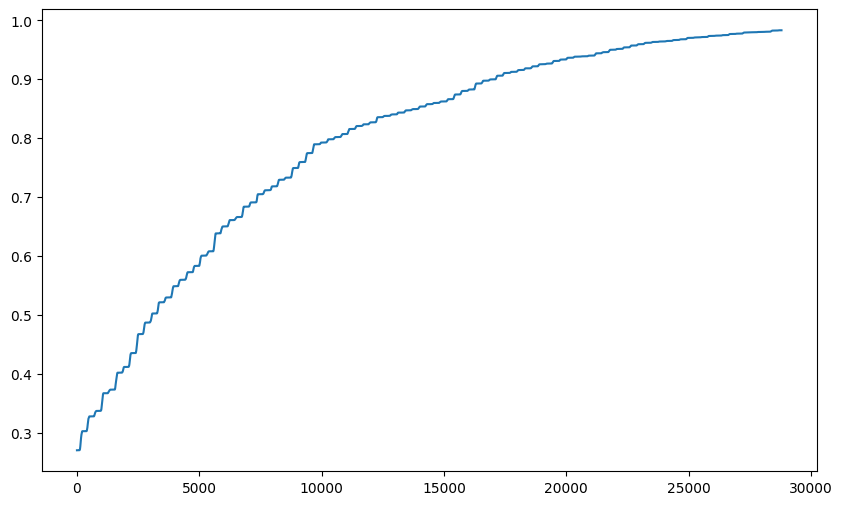

In [4]:
import numpy as np

fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111)
ax.plot(1 - np.exp(-0.7*crop_output["LAI"]))

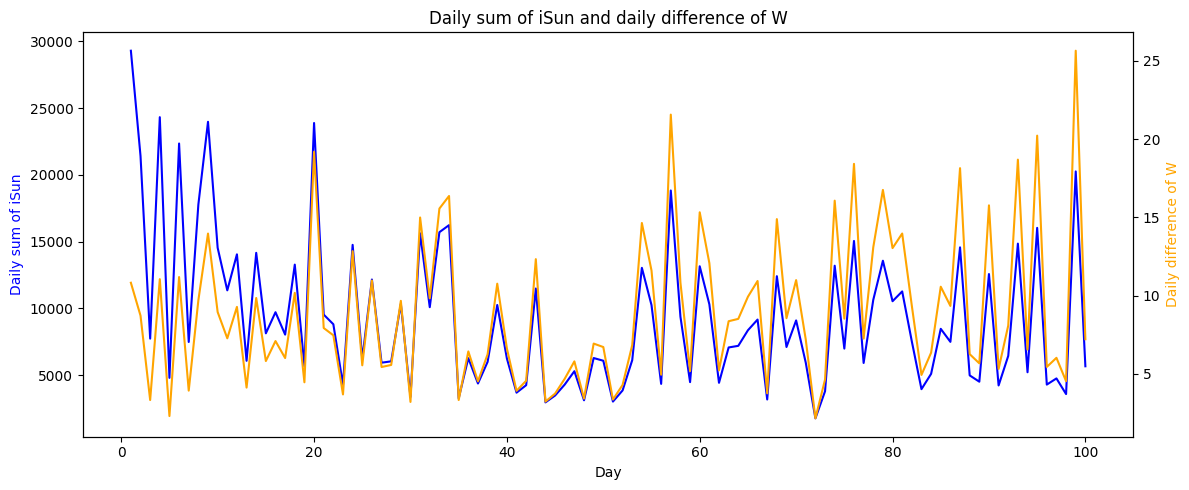

In [15]:
# Group rows into blocks of 288
groups = np.arange(len(crop_output)) // 288

daily_iSun = crop_output['iSun'].groupby(groups).sum()
daily_W = crop_output['W'].groupby(groups).agg(
    lambda x: x.iloc[-1] - x.iloc[0]
)

# Plot both daily values
fig, ax1 = plt.subplots(figsize=(12, 5))

days = np.arange(1, len(daily_iSun) + 1)

ax1.plot(days, daily_iSun, color='blue')
ax1.set_xlabel('Day')
ax1.set_ylabel('Daily sum of iSun', color='blue')

ax2 = ax1.twinx()
ax2.plot(days, daily_W, color='orange')
ax2.set_ylabel('Daily difference of W', color='orange')

plt.title('Daily sum of iSun and daily difference of W')
fig.tight_layout()
plt.show()